In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score

df=pd.read_csv("dataset_medium_customer_churn.csv")
print(df["churn"].value_counts)


<bound method IndexOpsMixin.value_counts of 0      Yes
1      Yes
2      Yes
3      Yes
4      Yes
      ... 
495     No
496     No
497     No
498    Yes
499    Yes
Name: churn, Length: 500, dtype: str>


In [2]:
y=df["churn"].map({"Yes":1, "No":0})
X=df.drop(columns=["churn"])

numeric_features=["tenure_months", "monthly_charges","support_calls"]
categorical_features=["contract_type","internet_service"]

preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)
X_train, X_test, y_train,y_test=train_test_split(
    X,y,test_size=.25, random_state=42, stratify=y
)
X_train_pre=preprocessor.fit_transform(X_train)
X_test_pre=preprocessor.transform(X_test)
print("train shape: ", X_train_pre.shape)
print("test shape: ", X_test_pre.shape) 
print("train churn mean: ", y_train.mean())
print("test churn mean: ", y_test.mean())


train shape:  (375, 9)
test shape:  (125, 9)
train churn mean:  0.432
test churn mean:  0.432


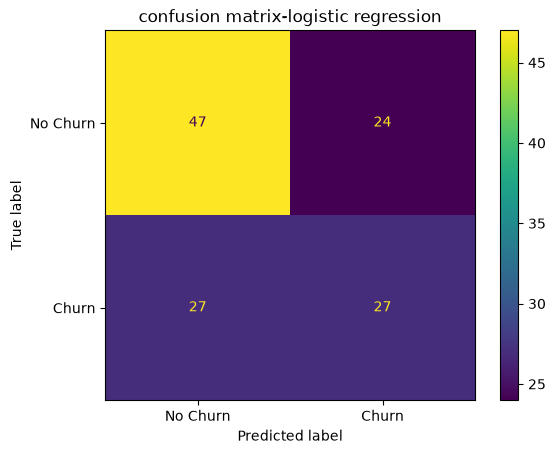

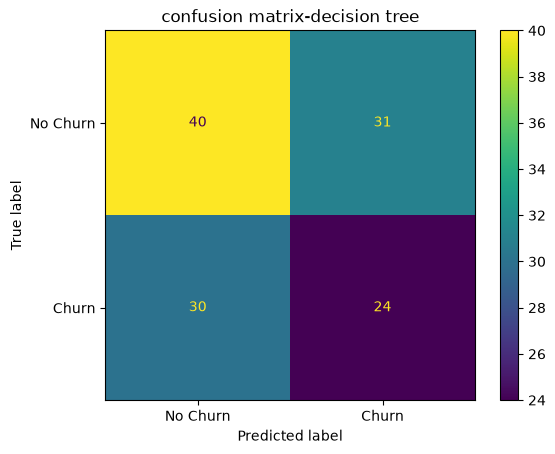

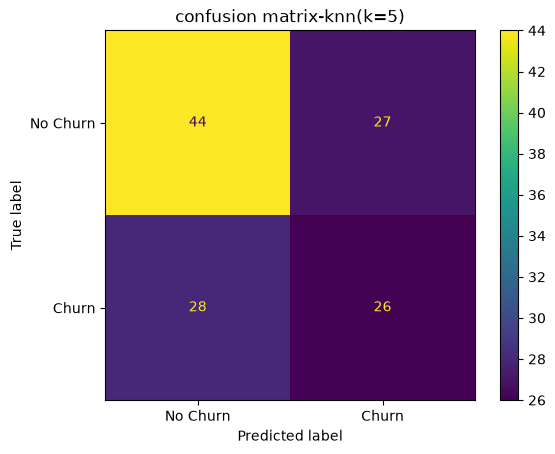

,Model,Accuracy,Precision,Recall,F1,AUC
0,logistic regression,0.592,0.529412,0.500000,0.514286,0.636672
1,decision tree,0.512,0.436364,0.444444,0.440367,0.503912
2,knn(k=5),0.560,0.490566,0.481481,0.485981,0.600809


In [3]:
models={
    "logistic regression": LogisticRegression(max_iter=1000, random_state=42),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "knn(k=5)": KNeighborsClassifier(n_neighbors=5)
}
results=[]
for name,model in models.items():
    model.fit(X_train_pre,y_train)

    y_pred=model.predict(X_test_pre)
    y_prob=model.predict_proba(X_test_pre)[:,1]

    accuracy=accuracy_score(y_test,y_pred)
    precision=precision_score(y_test, y_pred, zero_division=0)
    recall=recall_score(y_test, y_pred,zero_division=0)
    f1=f1_score(y_test, y_pred,zero_division=0)
    roc_auc=roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "AUC": roc_auc
    })
    
    display=ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["No Churn", "Churn"]
    )    
    display.ax_.set_title(f"confusion matrix-{name}")
    plt.show()

pd.DataFrame(results)

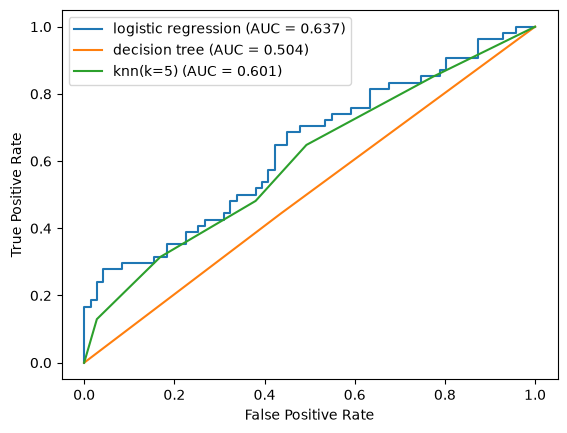

In [9]:
for name, model in models.items():
    model.fit(X_train_pre, y_train)
    y_prob = model.predict_proba(X_test_pre)[:, 1]      
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")                 
plt.legend()
plt.show()

REPORT QUESTION ASNWER
1)Logistic Regression gave the best overall performance because it achieved the highest F1-score and the highest auc. It means it balanced precesion and recall better than any other model. 
2) I would prioritize the model with the highest recall and that is Logistic Regression. The higher the recall, the lower missed churners.
3)changing k changed the KNN's performance.When K is small, the model becomes sennsitive as it only looks at 3 neighbors.Large K makes it smoother but biased.